# Lattice core — `discuspdf.Lattice`

Examples of the lattice and coordinate utilities added in Package A, Feature A5 (PR #10).
Everything here is pure NumPy; DISCUS is not needed.

**Conventions** (shared with the DISCUS 3D reader, `DiscusVolume`):

| Quantity | Convention |
|---|---|
| Direct basis `A` | 3×3, rows are **a**, **b**, **c** in Å |
| Fractional → Cartesian | `r = f @ A` (row vectors) |
| Reciprocal basis `B` | `B = inv(A).T`, rows **a\***, **b\***, **c\*** in Å⁻¹, no 2π |
| Cartesian Q | `Q = 2π · (hkl @ B)` in Å⁻¹; hkl in r.l.u. |
| d-spacing | `d = 1 / |hkl @ B|` in Å |
| Angles | degrees; lengths in Å |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from discuspdf import Lattice

np.set_printoptions(precision=6, suppress=True)

## 1. Building a lattice

`from_parameters` takes the six cell parameters and uses the canonical orientation
(**a** along x, **b** in the xy plane, right-handed).

In [2]:
cubic = Lattice.from_parameters(5.0, 5.0, 5.0, 90, 90, 90)
tric = Lattice.from_parameters(4.1, 5.3, 6.7, 78, 95, 112)

print(cubic)
print(tric)
print("\nTriclinic direct basis A (rows a, b, c, Å):")
print(tric.matrix)

Lattice(a=5 Å, b=5 Å, c=5 Å, alpha=90°, beta=90°, gamma=90°, V=125 Å³)
Lattice(a=4.1 Å, b=5.3 Å, c=6.7 Å, alpha=78°, beta=95°, gamma=112°, V=132.033 Å³)

Triclinic direct basis A (rows a, b, c, Å):
[[ 4.1       0.        0.      ]
 [-1.985415  4.914074  0.      ]
 [-0.583943  1.266479  6.553247]]


The six parameters are recovered from the stored basis, and the volume agrees with the
closed-form triclinic formula.

In [3]:
a, b, c, al, be, ga = 4.1, 5.3, 6.7, *np.deg2rad([78, 95, 112])
V_formula = a*b*c*np.sqrt(1 - np.cos(al)**2 - np.cos(be)**2 - np.cos(ga)**2
                          + 2*np.cos(al)*np.cos(be)*np.cos(ga))
print("parameters:", np.round(tric.parameters, 10))
print(f"volume: {tric.volume:.10f} Å³   closed form: {V_formula:.10f} Å³")

parameters: [  4.1   5.3   6.7  78.   95.  112. ]
volume: 132.0328787137 Å³   closed form: 132.0328787137 Å³


`from_matrix` keeps whatever (right-handed) orientation you give it. Here the cubic cell is
rotated 30° about z: same cell parameters and volume, different Cartesian frame.

In [4]:
t = np.deg2rad(30)
Rz = np.array([[np.cos(t), np.sin(t), 0], [-np.sin(t), np.cos(t), 0], [0, 0, 1]])
rotated = Lattice.from_matrix(cubic.matrix @ Rz)
print(rotated)
print("same parameters:", np.allclose(rotated.parameters, cubic.parameters))
print("same basis matrix:", rotated == cubic)

Lattice(a=5 Å, b=5 Å, c=5 Å, alpha=90°, beta=90°, gamma=90°, V=125 Å³)
same parameters: True
same basis matrix: False


## 2. Invalid cells fail loudly

Impossible or degenerate cells raise `ValueError` instead of returning NaNs.

In [5]:
bad_inputs = {
    "negative length":           lambda: Lattice.from_parameters(-5, 5, 5, 90, 90, 90),
    "angle of 180°":             lambda: Lattice.from_parameters(5, 5, 5, 90, 90, 180),
    "impossible angles":         lambda: Lattice.from_parameters(5, 5, 5, 10, 10, 170),
    "left-handed matrix":        lambda: Lattice.from_matrix(np.diag([5.0, 5.0, -5.0])),
    "singular matrix":           lambda: Lattice.from_matrix([[1, 0, 0], [2, 0, 0], [0, 0, 1]]),
    "d-spacing of (0,0,0)":      lambda: cubic.d_spacing((0, 0, 0)),
}
for name, call in bad_inputs.items():
    try:
        call()
        print(f"{name:22s} -> accepted (unexpected)")
    except ValueError as err:
        print(f"{name:22s} -> ValueError: {err}")

negative length        -> ValueError: unit cell lengths must be three finite positive values in Å
angle of 180°          -> ValueError: unit cell angles must be finite degrees strictly between 0 and 180
impossible angles      -> ValueError: Invalid or degenerate unit cell: metric is not positive definite
left-handed matrix     -> ValueError: lattice matrix is singular (det = 0) or left-handed (det < 0); got det = -125. Only right-handed cells (det > 0) are supported.
singular matrix        -> ValueError: lattice matrix is singular (det = 0) or left-handed (det < 0); got det = 0. Only right-handed cells (det > 0) are supported.
d-spacing of (0,0,0)   -> ValueError: d_spacing is undefined for hkl = (0, 0, 0)


## 3. Fractional ↔ Cartesian coordinates

Inputs can be a single vector or an array with any leading shape.

In [6]:
f = np.array([0.25, 0.5, 0.75])
r = tric.frac_to_cart(f)
print("f =", f, "-> r =", r, "Å")
print("back to fractional:", tric.cart_to_frac(r))

rng = np.random.default_rng(0)
F = rng.uniform(-1, 2, size=(4, 1000, 3))          # leading shape (4, 1000)
err = np.abs(tric.cart_to_frac(tric.frac_to_cart(F)) - F).max()
print(f"round trip on shape {F.shape}: max error {err:.1e}")

f = [0.25 0.5  0.75] -> r = [-0.405665  3.406897  4.914935] Å
back to fractional: [0.25 0.5  0.75]
round trip on shape (4, 1000, 3): max error 6.7e-16


## 4. Reciprocal space: Q and d-spacings

For the cubic cell, |Q(100)| = 2π/5 Å⁻¹ and d₁₀₀ = 5 Å.

In [7]:
q100 = cubic.hkl_to_q((1, 0, 0))
print("Q(100) =", q100, "Å⁻¹   |Q| =", np.linalg.norm(q100), "  2π/5 =", 2*np.pi/5)
print("d_100 =", cubic.d_spacing((1, 0, 0)), "Å;  d_111 =", cubic.d_spacing((1, 1, 1)), "=", 5/np.sqrt(3))

Q(100) = [ 1.256637 -0.       -0.      ] Å⁻¹   |Q| = 1.2566370614359172   2π/5 = 1.2566370614359172
d_100 = 5.0 Å;  d_111 = 2.8867513459481287 = 2.886751345948129


Triclinic d-spacings match the textbook formula
1/d² = (h²b²c²sin²α + … ) / V², computed here independently of `Lattice`.

In [8]:
def d_textbook(h, k, l, a, b, c, al, be, ga):
    ca, cb, cg = np.cos([al, be, ga]); sa, sb, sg = np.sin([al, be, ga])
    V = a*b*c*np.sqrt(1 - ca**2 - cb**2 - cg**2 + 2*ca*cb*cg)
    s = (h*h*b*b*c*c*sa**2 + k*k*a*a*c*c*sb**2 + l*l*a*a*b*b*sg**2
         + 2*h*k*a*b*c*c*(ca*cb - cg) + 2*k*l*a*a*b*c*(cb*cg - ca) + 2*h*l*a*b*b*c*(ca*cg - cb))
    return V / np.sqrt(s)

print(" hkl        Lattice.d_spacing   textbook")
for hkl in [(1, 0, 0), (0, 1, 0), (1, 1, 0), (1, -1, 2), (2, 3, -1)]:
    print(f" {str(hkl):10s} {tric.d_spacing(hkl):12.8f}   {d_textbook(*hkl, a, b, c, al, be, ga):12.8f}")

 hkl        Lattice.d_spacing   textbook
 (1, 0, 0)    3.80125519     3.80125519
 (0, 1, 0)    4.82479879     4.82479879
 (1, 1, 0)    2.56444808     2.56444808
 (1, -1, 2)   2.28779647     2.28779647
 (2, 3, -1)   1.02037285     1.02037285


Q and hkl convert both ways, and the 2π convention is consistent with real space:
Q·r = 2π (hkl·f) for any hkl and fractional point f.

In [9]:
HKL = rng.integers(-5, 6, size=(1000, 3))
Fpts = rng.uniform(0, 1, size=(1000, 3))
lhs = np.einsum("ij,ij->i", tric.hkl_to_q(HKL), tric.frac_to_cart(Fpts))
rhs = 2*np.pi*np.einsum("ij,ij->i", HKL, Fpts)
print(f"max |Q·r − 2π hkl·f| = {np.abs(lhs - rhs).max():.1e}")
print(f"hkl -> Q -> hkl max error = {np.abs(tric.q_to_hkl(tric.hkl_to_q(HKL)) - HKL).max():.1e}")
print("A @ Bᵀ = I:", np.allclose(tric.matrix @ tric.reciprocal_matrix.T, np.eye(3)))
print("G @ G* = I:", np.allclose(tric.metric @ tric.reciprocal_metric, np.eye(3)))

max |Q·r − 2π hkl·f| = 2.1e-14
hkl -> Q -> hkl max error = 1.8e-15
A @ Bᵀ = I: True
G @ G* = I: True


## 5. Periodic boundaries and the minimum image

In a strongly skewed cell, rounding each fractional component to the nearest integer does
**not** always give the shortest periodic image. `minimum_image` uses an exact bounded search.
Below, in a cell with γ = 20°, points under the diagonal are displacements where rounding
picks the wrong image.

rounding gives the wrong image for 24.3% of displacements; worst overestimate 3.87 Å


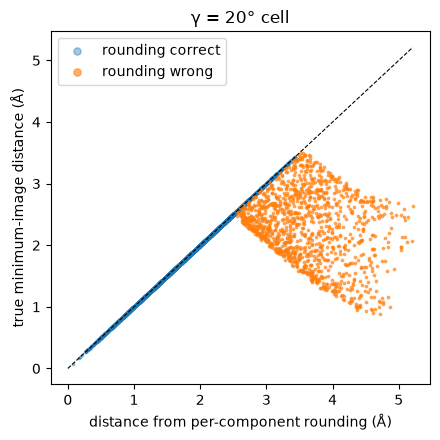

In [10]:
skew = Lattice.from_parameters(5, 5, 5, 90, 90, 20)
df = rng.uniform(-0.5, 0.5, size=(5000, 3))
naive = np.linalg.norm((df - np.rint(df)) @ skew.matrix, axis=1)
df_min, shift = skew.minimum_image(df)
true = np.linalg.norm(df_min @ skew.matrix, axis=1)

wrong = true < naive - 1e-9
print(f"rounding gives the wrong image for {wrong.mean():.1%} of displacements; "
      f"worst overestimate {np.max(naive - true):.2f} Å")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(naive[~wrong], true[~wrong], s=3, alpha=0.4, label="rounding correct")
ax.scatter(naive[wrong], true[wrong], s=3, alpha=0.6, label="rounding wrong")
m = naive.max()
ax.plot([0, m], [0, m], "k--", lw=0.8)
ax.set_xlabel("distance from per-component rounding (Å)")
ax.set_ylabel("true minimum-image distance (Å)")
ax.set_title("γ = 20° cell")
ax.legend(markerscale=3)
plt.tight_layout()

**Ties.** When two images are equally short (for example exactly half a lattice vector),
the one whose reduced fractional vector is lexicographically smallest is returned, so the
answer depends only on the displacement modulo whole lattice vectors. In a cubic cell, half-cell
ties land in [−½, ½).

In [11]:
for d in [(0.5, 0, 0), (-0.5, 0, 0), (1.5, 0, 0), (0.5, 0.5, 0)]:
    red, n = cubic.minimum_image(np.array(d, float))
    print(f"{str(d):18s} -> reduced {red}, shift {n}")

# adding whole lattice vectors never changes the result
d = rng.uniform(-0.5, 0.5, size=(2000, 3))
n = rng.integers(-50, 51, size=d.shape)
same = np.allclose(skew.minimum_image(d + n)[0], skew.minimum_image(d)[0], atol=1e-9)
print("\ntranslation invariant over 2000 random shifts:", same)

(0.5, 0, 0)        -> reduced [-0.5  0.   0. ], shift [1 0 0]
(-0.5, 0, 0)       -> reduced [-0.5  0.   0. ], shift [0 0 0]
(1.5, 0, 0)        -> reduced [-0.5  0.   0. ], shift [2 0 0]
(0.5, 0.5, 0)      -> reduced [-0.5 -0.5  0. ], shift [1 1 0]



translation invariant over 2000 random shifts: True


`distance_pbc` gives the minimum-image distance between two fractional points.

In [12]:
print("cubic,  (0,0,0)–(0.9,0,0):", cubic.distance_pbc((0, 0, 0), (0.9, 0, 0)), "Å")
print("skewed, (0,0,0)–(0.6,0.6,0):", round(skew.distance_pbc((0, 0, 0), (0.6, 0.6, 0)), 6), "Å")
print("   straight-line, no wrapping:", round(float(np.linalg.norm(np.array([0.6, 0.6, 0]) @ skew.matrix)), 6), "Å")

cubic,  (0,0,0)–(0.9,0,0): 0.4999999999999999 Å
skewed, (0,0,0)–(0.6,0.6,0): 1.312893 Å
   straight-line, no wrapping: 5.908847 Å


## 6. Lattices are immutable values

Getters return copies, the stored arrays are read-only, and attributes cannot be changed.
That makes a `Lattice` safe to share between structures.

In [13]:
A = cubic.matrix
A[0, 0] = 999.0
print("editing the returned copy leaves the lattice unchanged:", cubic.matrix[0, 0])

for attempt in ["cubic._A[0, 0] = 1.0", "cubic._A = np.eye(3)", "cubic.label = 'x'"]:
    try:
        exec(attempt)
        print(f"{attempt:24s} -> allowed (unexpected)")
    except (ValueError, AttributeError) as err:
        print(f"{attempt:24s} -> {type(err).__name__}")

print("\nequal:", cubic == Lattice.from_parameters(5, 5, 5, 90, 90, 90),
      "| isclose to a 5.0000000001 Å cell:", cubic.isclose(Lattice.from_parameters(5.0000000001, 5, 5, 90, 90, 90), rtol=1e-9))

editing the returned copy leaves the lattice unchanged: 5.0
cubic._A[0, 0] = 1.0     -> ValueError
cubic._A = np.eye(3)     -> AttributeError
cubic.label = 'x'        -> AttributeError

equal: True | isclose to a 5.0000000001 Å cell: True


## Not yet available

The editable `Structure` model, CIF/ASE/DiffPy adapters, DISCUS `.cll`/`.stru` reading and
writing, and supercell editing are the next Package A pull requests. They will build on
`Lattice`. See `docs/LATTICE.md` for the full API.